# Inspect the audio files

This notebook reports basic properties and plots waveforms for the two separate recordings. It does not combine or modify them, and does not treat them as matching stems.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

try:
    import soundfile as sf
except ImportError:
    sf = None
    print("The soundfile package is required to read OGG audio. Install it in this notebook's selected Python environment, then restart the kernel and run the notebook again.")

In [6]:
root_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in root_candidates if (candidate / "data").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing the data folder.")

audio_files = {
    "Sitar recording": PROJECT_ROOT / "data" / "Sohini_Qawwali.ogg",
    "Tabla recording": PROJECT_ROOT / "data" / "Tabla_drums_demo.oga",
}

print(f"Project root: {PROJECT_ROOT}")
for label, path in audio_files.items():
    print(f"{label}: {path}")

Project root: d:\indian-instrument-separation
Sitar recording: d:\indian-instrument-separation\data\Sohini_Qawwali.ogg
Tabla recording: d:\indian-instrument-separation\data\Tabla_drums_demo.oga


In [7]:
audio_data = {}
audio_info = {}

for label, path in audio_files.items():
    try:
        if not path.is_file():
            raise FileNotFoundError(f"Audio file not found: {path}")
        if sf is None:
            raise ImportError("Install the soundfile package in the selected Python environment to load OGG audio.")

        samples, sample_rate = sf.read(path, always_2d=True)
        invalid_values = not np.isfinite(samples).all()
        info = {
            "success": True,
            "duration": samples.shape[0] / sample_rate,
            "sample_rate": sample_rate,
            "channels": samples.shape[1],
            "number_of_samples": samples.shape[0],
            "data_type": str(samples.dtype),
            "has_invalid_values": invalid_values,
        }
        audio_data[label] = samples
        audio_info[label] = info

    except Exception as error:
        audio_info[label] = {"success": False, "error": str(error)}

    info = audio_info[label]
    print(f"\n{label}")
    print(f"  Loading succeeded: {info['success']}")
    if info["success"]:
        print(f"  Duration: {info['duration']:.2f} seconds")
        print(f"  Sample rate: {info['sample_rate']} Hz")
        print(f"  Audio channels: {info['channels']}")
        print(f"  Number of samples: {info['number_of_samples']}")
        print(f"  Data type: {info['data_type']}")
        print(f"  Contains NaN or infinity: {info['has_invalid_values']}")
    else:
        print(f"  Loading error: {info['error']}")


Sitar recording
  Loading succeeded: True
  Duration: 170.58 seconds
  Sample rate: 44100 Hz
  Audio channels: 2
  Number of samples: 7522560
  Data type: float64
  Contains NaN or infinity: False

Tabla recording
  Loading succeeded: True
  Duration: 156.75 seconds
  Sample rate: 44100 Hz
  Audio channels: 2
  Number of samples: 6912531
  Data type: float64
  Contains NaN or infinity: False


C:\Users\gicsc\AppData\Local\Temp\ipykernel_17524\1077528145.py:13: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
d:\Miniconda3\envs\ml\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


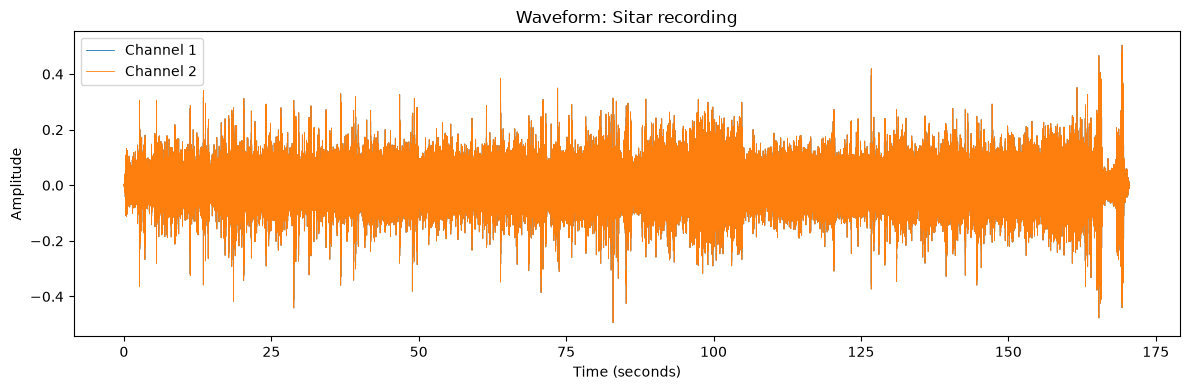

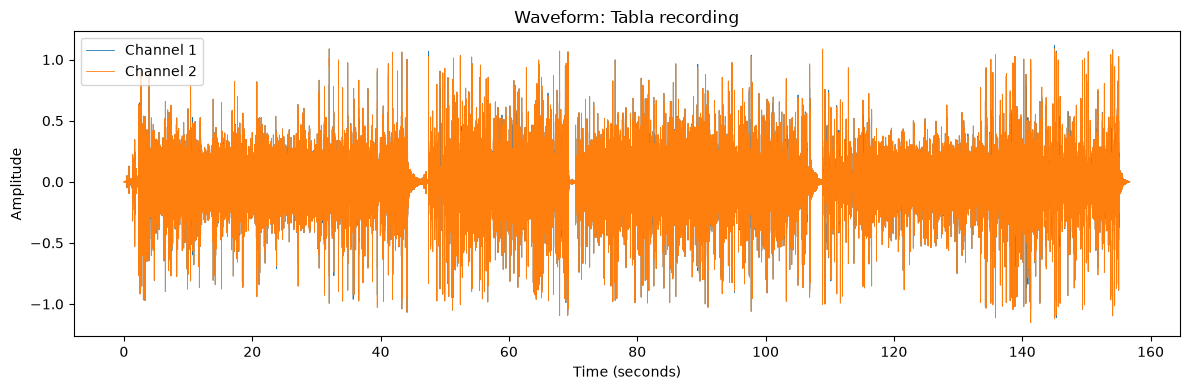

In [8]:
for label, samples in audio_data.items():
    sample_rate = audio_info[label]["sample_rate"]
    time_seconds = np.arange(samples.shape[0]) / sample_rate

    plt.figure(figsize=(12, 4))
    for channel in range(samples.shape[1]):
        plt.plot(time_seconds, samples[:, channel], label=f"Channel {channel + 1}", linewidth=0.6)

    plt.title(f"Waveform: {label}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.tight_layout()
    plt.show()